## SOAL 2: Analisis Invarian, Bifurkasi Fasa, dan Stabilitas Numerik pada Model Predator–Prey Lotka–Volterra

In [69]:
#Konstanta

a = 2.0
b = 0.02
c = 0.01
d = 1.06

Interaksi antara populasi mangsa (prey, disimbolkan $x(t)$) dan pemangsa (predator, disimbolkan $y(t)$) dimodelkan melalui persamaan diferensial nonlinier Lotka–Volterra:

$$\frac{dx}{dt} = \alpha x - \beta xy$$

$$\frac{dy}{dt} = \delta xy - \gamma y$$

In [70]:
import numpy as np

def f(t, Y):
  x = Y[0]
  y = Y[1]
  dxdt = a*x - b*x*y
  dydt = c*x*y - d*y
  return np.array([dxdt, dydt])

Fungsi kekekalan (*first integral / conserved quantity*):

$$V(x,y) = \delta x - \gamma ln(x) + \beta y - \alpha ln(y)$$

In [71]:
def V(x, y):
  return c*x - d*np.log(x) + b*y - a*np.log(y)

### 1. Analisis Analitik Ekuilibrium & Linearitas:

#### a. Tentukan titik kesetimbangan non-trivial sistem $(x^*, y^*)$.

$\left. \begin{array}{l} \frac{dx}{dt} = 0 \\ \alpha x - \beta xy^* = 0 \\ x(\alpha - \beta y^*) = 0 \end{array} \right\rbrace \begin{array}{l}x = 0 \\ \alpha - \beta y^* = 0 \end{array}$

$\quad$

$\alpha - \beta y^* = 0$

$\beta y^* = \alpha$

$y^* = \frac{\alpha}{\beta}$

$y^* = \frac{2}{0.02} = 100$

$\left. \begin{array}{l} \frac{dy}{dt} = 0 \\ \delta x^*y - \gamma y = 0 \\ y(\delta x^* - \gamma) = 0 \end{array} \right\rbrace \begin{array}{l}y = 0 \\ \delta x^* - \gamma = 0 \end{array}$

$\quad$

$\delta x^* - \gamma = 0$

$\delta x^* = \gamma$

$x^* = \frac{\gamma}{\delta}$

$x^* = \frac{1.06}{0.01} = 106$

$(x^*, y^*) = (106, 100)$

#### b. Turunkan matriks Jacobian $J(x^*, y^*)$ dan hitung nilai-nilai eigennya $(\lambda_{1,2})$. Buktikan secara teoretis bahwa titik kesetimbangan tersebut adalah sebuah center (stabil netral/marginal).

$\frac{dx}{dt} = f(x,y) = \alpha x - \beta xy, \quad \frac{dy}{dt} = g(x,y) = \delta xy - \gamma y$

$\quad$

$J(x,y) = \begin{bmatrix} \frac{\delta f}{\delta x} & \frac{\delta f}{\delta y} \\ \frac{\delta g}{\delta x} & \frac{\delta g}{\delta y} \end{bmatrix}$

$\frac{\delta f}{\delta x} = \alpha - \beta y, \quad \frac{\delta f}{\delta y} = - \beta x$

$\frac{\delta g}{\delta x} = \delta y, \quad \frac{\delta g}{\delta y} = \delta x - \gamma$

$J(x,y) = \begin{bmatrix} \alpha - \beta y & - \beta x \\ \delta y & \delta x - \gamma \end{bmatrix}$

$\quad$

Subsitusi $(x^*, y^*) = (106, 100)$:

$J* = \begin{bmatrix} 2-0.02(100) & -0.02(106) \\ 0.01(100) & 0.01(106)-1.06 \end{bmatrix}$

$J* = \begin{bmatrix} 0 & -2.12 \\ 1.0 & 0 \end{bmatrix}$

Nilai eigen:

$det(J^* - \lambda I) = 0$

$\begin{vmatrix} - \lambda & -2.12 \\ 1.0 & - \lambda \end{vmatrix} = 0$

$(-\lambda) (-\lambda) - (-2.12)(1.0) = 0$

$\lambda^2 + 2.12 = 0$

$\lambda^2 = -2.12$

$\lambda = \pm i\sqrt{2.12}, \pm 1.456i$

#### c. Buktikan secara analitis bahwa $\frac{dV}{dt} = 0$ di sepanjang solusi sistem persamaan diferensial.

$\frac{dV}{dt} = \frac{\delta V}{\delta x} \frac{dx}{dt} + \frac{\delta V}{\delta y} \frac{dy}{dt}$

$\quad$

Turunan parsial:

$\frac{dV}{dx} = \delta - \frac{\gamma}{x}, \quad \frac{\delta V}{\delta y} = \beta - \frac{\alpha}{y}$

$\quad$

Subsitusi $\frac{dx}{dt} = \alpha x - \beta xy, \quad \frac{dy}{dt} = \delta xy - \gamma y$ :

$\frac{dV}{dt} = (\delta - \frac{\gamma}{x}) (\alpha x - \beta xy) + (\beta - \frac{\alpha}{y}) (\delta xy - \gamma y)$

$\frac{dV}{dt} = (\delta - \frac{\gamma}{x}) x (\alpha - \beta y) + (\beta - \frac{\alpha}{y}) y (\delta x - \gamma)$

$\frac{dV}{dt} = (\delta x - \gamma) (\alpha - \beta y) + (\beta y - \alpha) (\delta x - \gamma)$

$\frac{dV}{dt} = (\delta x - \gamma) (\alpha - \beta y) - (\alpha - \beta y) (\delta x - \gamma)$

$\frac{dV}{dt} = 0$

### 2. Implementasi Komparasi Numerik (Euler vs. RK4):

Tulis program untuk menyelesaikan sistem persamaan diferensial di atas dari $t = 0$ hingga $t = 24$ bulan dengan kondisi awal standar $(x_0, y_0) = (100,15)$ dengan $\Delta t = 0.005$ bulan

#### a. Metode A: Forward Euler
$$y_n = y_{n-1} + hf'(y_{n-1})$$
$$t_n = t_{n-1} + h$$

In [72]:
h = 0.005

t = 0
Y = np.array([100,15])
eul = [[], [], [], []]
x = Y[0]
y = Y[1]

while(t < 24):
  x += h*f(t, [x, y])[0]
  y += h*f(t, [x, y])[1]
  t += h
  v = V(x,y)
  eul[0].append(t)
  eul[1].append(x)
  eul[2].append(y)
  eul[3].append(v)

#### b. Metode B: *Classical Runge-Kutta Orde 4* (RK4)

$$k_1 = f(t_n, y_n)$$

$$k_2 = f(t_n + \frac{h}{2}, y_n + h\frac{k_1}{2})$$

$$k_3 = f(t_n + \frac{h}{2}, y_n + h\frac{k_2}{2})$$

$$k_4 = f(t_n + h, y_n + hk_3)$$

dimana:

$$y_{n} = y_{n-1} + \frac{1}{6}h(k_1+k_2+k_3+k_4)$$

$$t_n = t_{n-1} + h$$

In [73]:
def RK4(t, y):
  k1 = f(t, y)
  k2 = f(t + h/2, y + (h*k1/2))
  k3 = f(t + h/2, y + (h*k2/2))
  k4 = f(t + h, y + h*k3)
  return (1/6)*h*(k1+2*k2+2*k3+k4)

t = 0
Y = np.array([100,15])
rk = [[], [], [], []]
x = Y[0]
y = Y[1]

while(t < 24):
  Y = RK4(t, np.array([x, y]))
  x += Y[0]
  y += Y[1]
  t += h
  v = V(x, y)
  rk[0].append(t)
  rk[1].append(x)
  rk[2].append(y)
  rk[3].append(v)

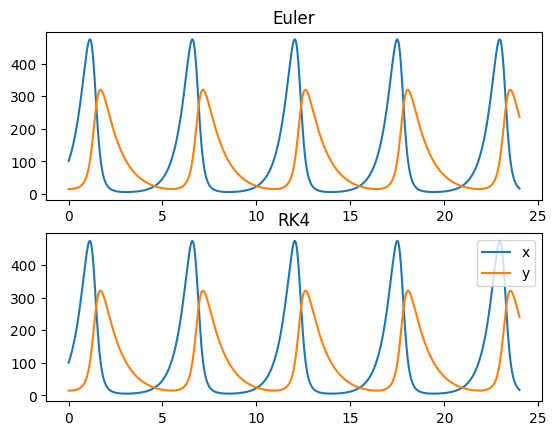

In [74]:
import matplotlib.pyplot as plt

fig, (ax1, ax2) = plt.subplots(2, 1)
ax1.plot(eul[0], eul[1], label='x')
ax1.plot(eul[0], eul[2], label='y')
ax1.set_title('Euler')

ax2.plot(rk[0], rk[1], label='x')
ax2.plot(rk[0], rk[2], label='y')
ax2.set_title('RK4')

plt.legend()
plt.show()

### 3. Visualisasi & Plot Komparatif:


#### a. Plot 1 (Siri Waktu RK4):
Dinamika populasi $x(t)$ dan $y(t)$ terhadap waktu dalam satu grafik.

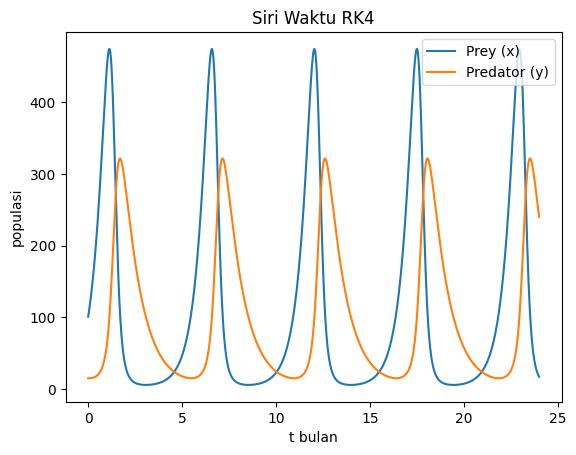

In [75]:
plt.plot(rk[0], rk[1], label='Prey (x)')
plt.plot(rk[0], rk[2], label='Predator (y)')
plt.title('Siri Waktu RK4')
plt.xlabel('t bulan')
plt.ylabel('populasi')
plt.legend()
plt.show()

#### b. Plot 2 (Multipel Trajektori Ruang Fasa):
Menggunakan solver RK4, plot orbit ruang fasa $(x, y)$ untuk 4 pasang kondisi awal berikut dalam satu bidang gambar:

$(x_0, y_0) = (100,15) \\ (x_0, y_0) = (125,75) \\ (x_0, y_0) = (150,135) \\ (x_0, y_0) = (175,195)$

Tandai pula posisi titik ekuilibrium $(x^*, y^*)$ dengan simbol khusus.

In [76]:
def phase(x0, y0):
  t = 0
  Y = np.array([x0,y0])
  sol = [[], [], []]
  x = Y[0]
  y = Y[1]

  while(t < 24):
    Y = RK4(t, np.array([x, y]))
    x += Y[0]
    y += Y[1]
    t += h
    sol[0].append(t)
    sol[1].append(x)
    sol[2].append(y)

  return [sol[1], sol[2]]

In [77]:
phase1 = phase(100, 15)
phase2 = phase(125, 75)
phase3 = phase(150,135)
phase4 = phase(175,195)

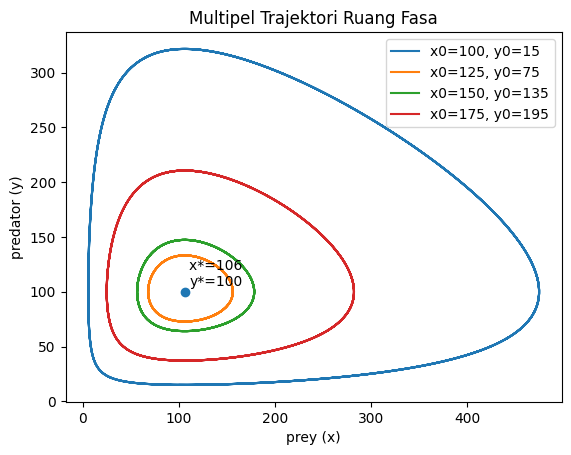

In [78]:
plt.plot(phase1[0], phase1[1], label='x0=100, y0=15')
plt.plot(phase2[0], phase2[1], label='x0=125, y0=75')
plt.plot(phase3[0], phase3[1], label='x0=150, y0=135')
plt.plot(phase4[0], phase4[1], label='x0=175, y0=195')

plt.title('Multipel Trajektori Ruang Fasa')
plt.xlabel('prey (x)')
plt.ylabel('predator (y)')

plt.scatter(106, 100)
plt.text(106 + 5, 100 + 5, 'x*=106 \ny*=100')

plt.legend()
plt.show()

#### c. Plot 3 (*Conservation Error Drift*)


Hitung dan plot galat invariansi besaran $V(t)$ terhadap waktu:

$$\Delta V(t) = |V(x(t), y(t)) - V(x_0, y_0)|$$



Bandingkan $\Delta V(t)$ antara metode Forward Euler dan RK4 dalam skala semi-logaritmik.

In [79]:
x0 = rk[1][0]
y0 = rk[2][0]
deltaV_RK4 = []
for i in range(len(rk[0])):
  err = np.abs(V(rk[1][i],rk[2][i]) - V(x0, y0))
  deltaV_RK4.append(err)

x0 = eul[1][0]
y0 = eul[2][0]
deltaV_Eul = []
for i in range(len(eul[0])):
  err = np.abs(V(eul[1][i],eul[2][i]) - V(x0, y0))
  deltaV_Eul.append(err)

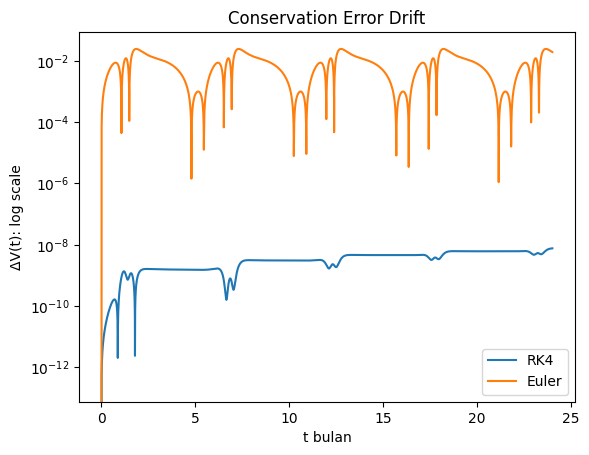

In [80]:
plt.plot(rk[0], deltaV_RK4, label='RK4')
plt.plot(eul[0], deltaV_Eul, label='Euler')
plt.yscale('log')

plt.title('Conservation Error Drift')
plt.xlabel('t bulan')
plt.ylabel('ΔV(t): log scale')

plt.legend()
plt.show()